## Regression Metrics

                    Regression Metrics
                           │
             ┌─────────────┴─────────────┐
             │                           │
       Prediction Error             Model Fit
             │                           │
       ┌─────┼─────┐                 ┌───┴────┐
       │     │     │                 │        │
      MAE   MSE   RMSE               R²    Adjusted R²
       │     │     │
       └─────┴─────┘
             │
     "How wrong are my
       predictions?"

### Mean Absolute Error (MAE)

Mean Absolute Error measures the average absolute difference between
the actual values and the predicted values.

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|
$$

Where:

- $n$ = Number of data points
- $y_i$ = Actual value
- $\hat{y}_i$ = Predicted value
- $|y_i - \hat{y}_i|$ = Absolute error


A lower MAE indicates that the predictions are closer to the actual values.

    - - Advantages
      - - Robust for outliers
        - MAE will result in the same unit
      - Disadvantages
      - - MAE Graph is not differentiable


          
### Mean Squared Error (MSE)

Mean Squared Error measures the average of the squared differences between the actual and predicted values.

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

Where:

- $n$ = Number of data points
- $y_i$ = Actual value
- $\hat{y}_i$ = Predicted value
- $(y_i - \hat{y}_i)^2$ = Squared error
  
    -  Advantages
      - - Can used as a loss function since it is differentiable
    -  Disadvantages
      - - Due to square if the data has outliers it will impact the result
    - If the data has outliers go with MAE or else go with MSE

      
## Root Mean Squared Error (RMSE)

RMSE is the square root of the Mean Squared Error (MSE).

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
$$

Where:

- $n$ = Number of data points
- $y_i$ = Actual value
- $\hat{y}_i$ = Predicted value
- $(y_i - \hat{y}_i)^2$ = Squared error
  - Advantages
    - Can used as loss function since it is differentiable and without square
  - Disadvantages
    - Not robust to outliers


## R² (R-Squared) (Coefficient of Determination or goodness of fit)

R² measures the proportion of the variance in the actual values that is explained by the model.

Generally, R² = 1 represents a perfect fit, while R² can also be negative when the model performs worse than simply predicting the mean of the target values

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Where:

- $n$ = Number of data points
- $y_i$ = Actual value
- $\hat{y}_i$ = Predicted value
- $\bar{y}$ = Mean of the actual values
- $\sum(y_i-\hat{y}_i)^2$ = Residual Sum of Squares (RSS)
- $\sum(y_i-\bar{y})^2$ = Total Sum of Squares (TSS)


## Adjusted R2 Score

$$
R^2_{adj} = 1 - (1 - R^2)\frac{n - 1}{n - k - 1}
$$

Where:

- $R^2$ = R-squared
- $n$ = Number of observations (data points)
- $k$ = Number of predictor variables

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [11]:
df = pd.read_csv('data/placement.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package(in lpa)')

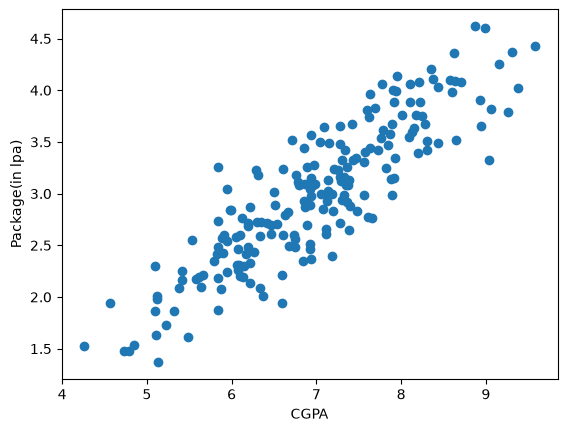

In [12]:
plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [13]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]

In [14]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [15]:
lr = LinearRegression()

In [16]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.56]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.8961
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Text(0, 0.5, 'Package(in lpa)')

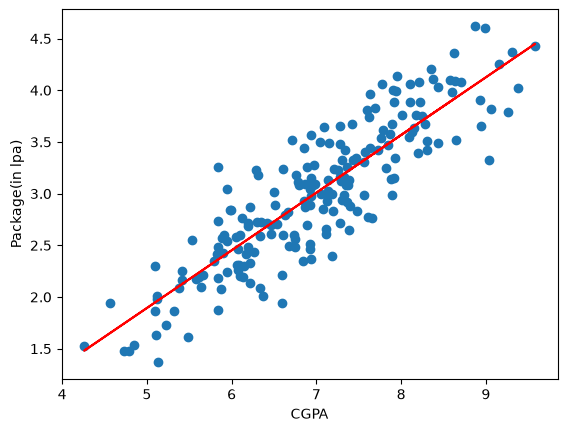

In [17]:
plt.scatter(df['cgpa'],df['package'])
plt.plot(X_train,lr.predict(X_train),color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [19]:
y_pred = lr.predict(X_test)

In [41]:
y_pred

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [20]:
y_test.values

array([4.1 , 3.49, 2.08, 2.33, 1.94, 1.48, 1.86, 3.09, 4.21, 2.87, 3.65,
       4.  , 2.89, 2.6 , 2.99, 3.25, 1.86, 3.67, 2.37, 3.42, 2.48, 3.65,
       2.6 , 2.83, 4.08, 2.56, 3.58, 3.81, 4.09, 2.01, 3.63, 2.92, 3.51,
       1.94, 2.21, 3.34, 3.34, 3.23, 2.01, 2.61])

In [32]:
X_test

,cgpa
112,8.58
29,7.15
182,5.88
199,6.22
193,4.57
85,4.79
10,5.32
54,6.86
115,8.35
35,6.87


In [34]:
df[df['cgpa'].isin(X_test['cgpa'])]

,cgpa,package
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57
6,6.73,2.60
7,6.75,2.48
9,8.31,3.51
10,5.32,1.86
12,8.94,3.65
13,6.93,2.89


In [35]:
print("MAE",mean_absolute_error(y_test,y_pred))

MAE 0.2884710931878175


In [36]:
print("MSE",mean_squared_error(y_test,y_pred))

MSE 0.12129235313495527


In [37]:
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))

RMSE 0.34827051717731616


In [38]:
print("MSE",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

MSE 0.780730147510384


In [39]:
# Adjusted R2 score
X_test.shape

(40, 1)

In [40]:
1 - ((1-r2)*(40-1)/(40-1-1))

0.7749598882343415

## RANDOM COLUMN

In [42]:
df2 = df.copy()
df2['dummy_feature'] = np.random.random(200)

df2 = df2[['cgpa','dummy_feature','package']]
df2.head()

,cgpa,dummy_feature,package
0,6.89,0.890545,3.26
1,5.12,0.454896,1.98
2,7.82,0.120752,3.25
3,7.42,0.708759,3.67
4,6.94,0.819462,3.57


In [43]:
df.shape

(200, 2)

In [44]:
df2.shape

(200, 3)

Text(0, 0.5, 'Package(in lpa)')

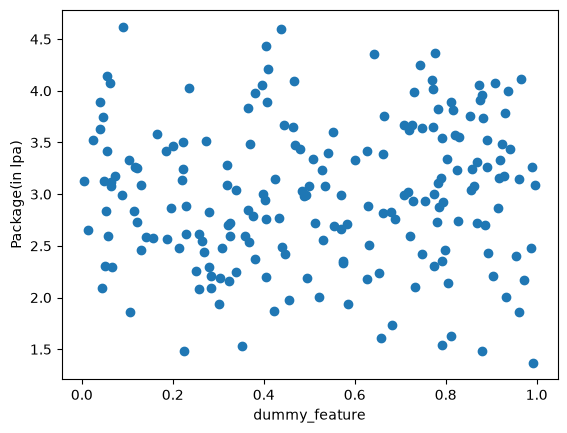

In [45]:
plt.scatter(df2['dummy_feature'],df2['package'])
plt.xlabel('dummy_feature')
plt.ylabel('Package(in lpa)')

In [47]:
X = df2.iloc[:,0:2]
y = df2.iloc[:,-1]

In [48]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [49]:
lr = LinearRegression()

In [50]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.56,0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cgpa','dummy_feature']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.9151
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [51]:
y_pred = lr.predict(X_test)

In [52]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.7841438561224686


In [53]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.7724759564534129

In [54]:
df3 = df.copy()

df3['iq'] = df3['package'] + (np.random.randint(-12,12,200)/10)

df3 = df3[['cgpa','iq','package']]

In [55]:
df3.sample(5)

,cgpa,iq,package
72,7.78,3.92,3.62
134,7.20,1.83,2.83
106,6.13,3.19,2.19
173,6.75,2.66,2.56
15,7.25,3.33,3.23


Text(0, 0.5, 'Package(in lpa)')

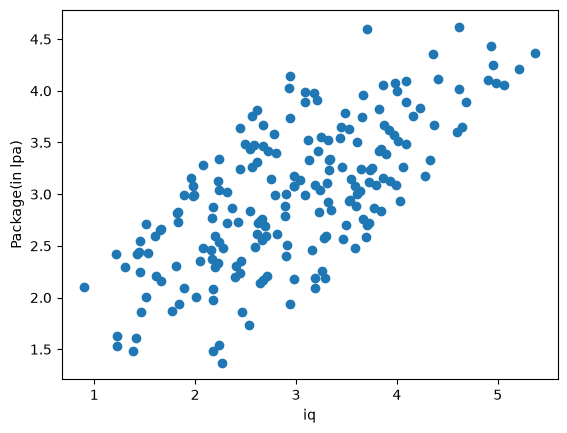

In [56]:
plt.scatter(df3['iq'],df3['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [57]:
np.random.randint(-100,100)

-74

In [59]:
X = df3.iloc[:,0:2]
y = df3.iloc[:,-1]

In [60]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [61]:

lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [62]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.8362571813286703


In [63]:
1 - ((1-r2)*(40-1)/(40-1-2))

0.8274062181572471